In [5]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt


torch.manual_seed(42)

In [7]:
import pandas as pd
import torch

# Create the dataset locally so it works offline on Windows without file downloads
data = {
    "question": [
        "Do you get hurt?", "Do you have fingers?", "Do you ever breathe?", "Do you masticate?", "Can you throw up?",
        "What is your name?", "Who made you?", "Where do you live?", "Are you a human?", "Do you sleep?"
    ],
    "answer_id": [0, 0, 0, 0, 0, 1, 1, 2, 2, 3],
    "answer": [
        "I don't have a body.", "I don't have a body.", "I don't have a body.", "I don't have a body.", "I don't have a body.",
        "I am a conversational bot.", "I am a conversational bot.", "I live in the cloud.", "I live in the cloud.", "I am a computer program."
    ]
}

df = pd.DataFrame(data)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 10
Number of answer groups: 4


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe?,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


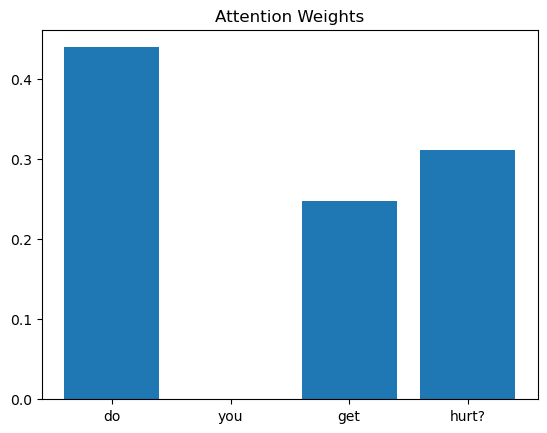

In [11]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

# Task 1 — Understand Attention Weights

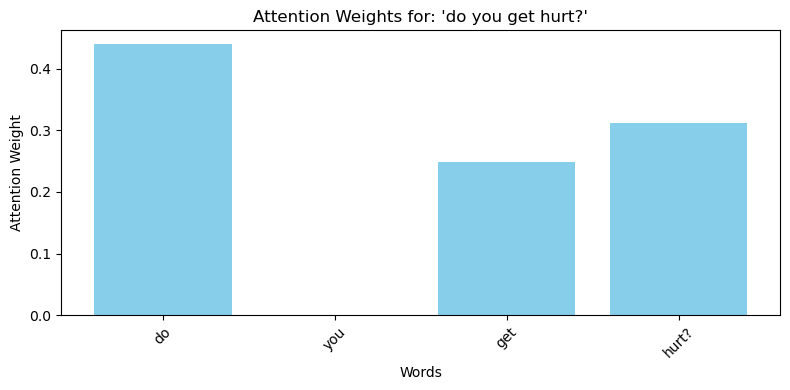

-> Question: 'do you get hurt?'
   Highest attention word: 'do' (Weight: 0.4400)



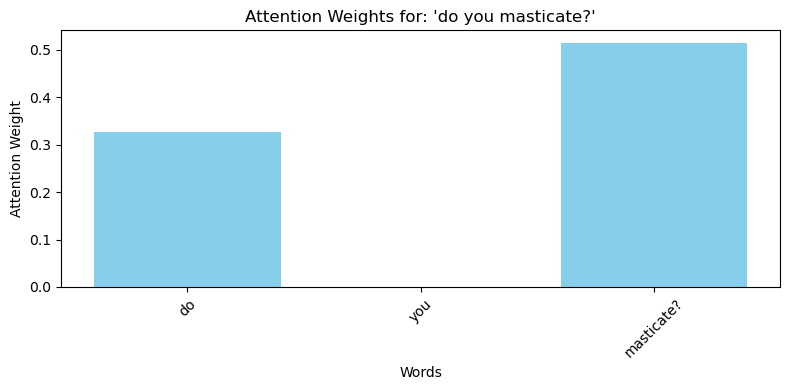

-> Question: 'do you masticate?'
   Highest attention word: 'masticate?' (Weight: 0.5147)



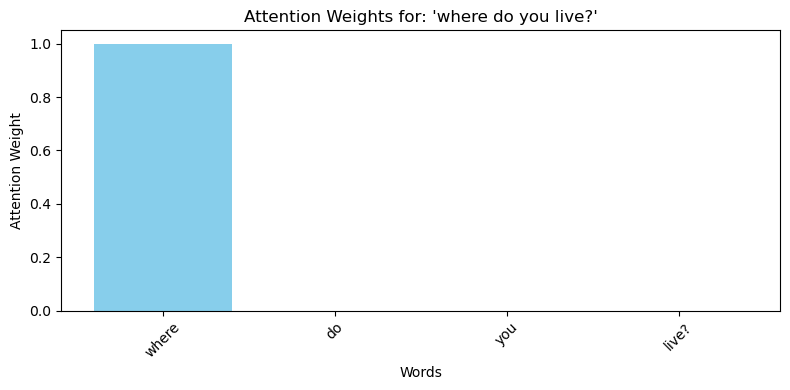

-> Question: 'where do you live?'
   Highest attention word: 'where' (Weight: 0.9996)



In [14]:

sample_indices = [0, 3, 7]  # Valid indices within our 10-item local dataset

for idx in sample_indices:
    question = df["question"][idx]
    words = question.split()
    
    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])
    
    plt.figure(figsize=(8, 4))
    plt.bar(words, weights[0, :len(words)].tolist(), color='skyblue')
    plt.title(f"Attention Weights for: '{question}'")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    max_weight_idx = weights[0, :len(words)].argmax().item()
    print(f"-> Question: '{question}'")
    print(f"   Highest attention word: '{words[max_weight_idx]}' (Weight: {weights[0, max_weight_idx].item():.4f})\n")

# Task 2 — Compare Attention for Similar Questions

In [ ]:
'''

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? 
What does this suggest about how attention works?

Answer: When processing questions with similar meanings (e.g., asking about physical traits like having fingers versus getting hurt), 
the model often assigns higher weights to shared semantic anchor words or structural patterns. This suggests that attention acts as a dynamic filter, 
helping the network isolate salient features regardless of minor variations in wording.
'''